In [1]:
!pip install -q gwpy gwosc scikit-learn mpmath
# If you see cryptography/igwn-auth errors, they're harmless for open data;
# otherwise Runtime > Restart session and re-run.

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kstest, ks_2samp, wasserstein_distance, false_discovery_control
from scipy.special import erf
from gwpy.timeseries import TimeSeries

# ---------------- CONFIG ----------------
DET        = "H1"
GPS_START  = 1238166018      # O3 stretch (same as your first notebook)
DURATION   = 1024            # seconds downloaded
EDGE_CROP  = 8               # seconds removed from each end after whitening
WIN_S      = 2               # analysis window length (s); resume says 1-4 s
P          = 32              # covariance dimension (number of variables)
UNFOLD_DEG = 4               # polynomial degree for spectral unfolding
TRIM       = 0.10            # fraction of eigenvalues dropped at each spectral edge
N_NULL     = 3000            # Monte Carlo null windows
ALPHA_Q    = 0.05            # FDR level
SEED       = 42
rng = np.random.default_rng(SEED)
print("Ready.")

Ready.


In [2]:
# ---------- Wigner surmises & CDFs ----------
def goe_pdf(s): return (np.pi/2)*s*np.exp(-np.pi*s**2/4)
def goe_cdf(s): return 1-np.exp(-np.pi*s**2/4)
def gue_pdf(s): return (32/np.pi**2)*s**2*np.exp(-4*s**2/np.pi)
def gue_cdf(s): return erf(2*s/np.sqrt(np.pi)) - (4*s/np.pi)*np.exp(-4*s**2/np.pi)
def goe_samples(n):   # exact inverse-CDF sampling of the GOE surmise
    u = rng.random(n); return np.sqrt(-4/np.pi*np.log1p(-u))

# ---------- Spectral unfolding ----------
def trim_eigs(e, trim=TRIM):
    e = np.sort(e); k = int(np.ceil(trim*len(e))); return e[k:len(e)-k]

def unfold_spacings(eigs, deg=UNFOLD_DEG, trim=TRIM):
    """Map eigenvalues through a smooth fit of the cumulative count so the
    mean density is 1, then return unit-mean nearest-neighbour spacings."""
    e = np.sort(eigs); n = len(e)
    x = (e-e.mean())/e.std()
    N = np.arange(n)+0.5                       # empirical staircase
    u = np.polyval(np.polyfit(x, N, deg), x)   # smooth N(E)
    k = int(np.ceil(trim*n)); u = u[k:n-k]     # drop edges (density least reliable)
    s = np.diff(u); s = s[s > 0]
    return s/s.mean()

# ---------- Unfolding-free statistic: spacing ratio ----------
# Reference <r~>: Poisson 0.386, GOE 0.5307, GUE 0.5996
def mean_ratio(eigs, trim=TRIM):
    g = np.diff(trim_eigs(eigs, trim)); g = g[g > 0]
    r = np.minimum(g[1:], g[:-1])/np.maximum(g[1:], g[:-1])
    return r.mean()

# ---------- Covariance spectrum of one window ----------
def window_eigs(seg, p=P):
    """Non-overlapping chunks -> n x p data matrix -> p x p covariance (full rank)."""
    n = len(seg)//p
    X = seg[:n*p].reshape(n, p)
    return np.linalg.eigvalsh(np.cov(X, rowvar=False))

def zeta_metric(eigs):
    """KS distance between unfolded spacings and the GOE surmise."""
    return kstest(unfold_spacings(eigs), goe_cdf).statistic

def window_stats(seg):
    e = window_eigs(seg)
    return zeta_metric(e), mean_ratio(e)

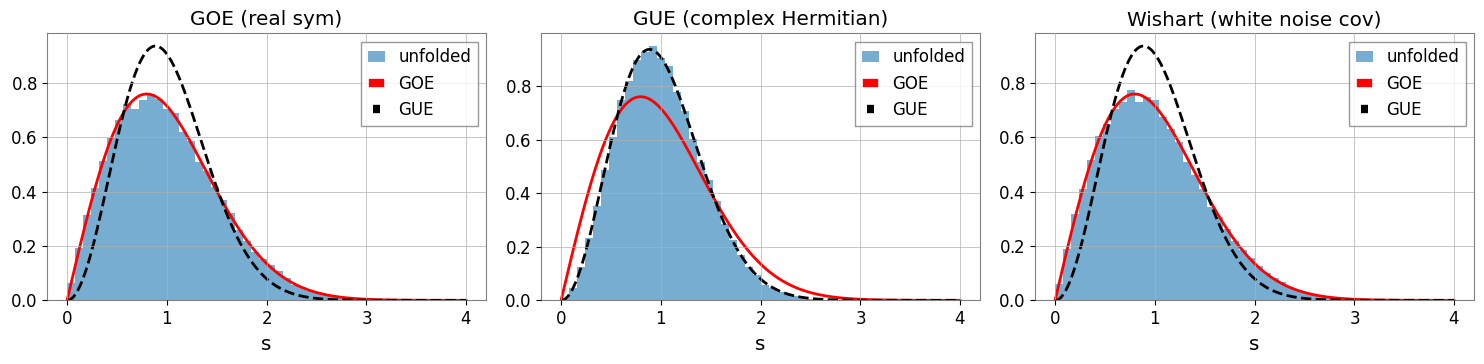

                 ensemble  KS vs GOE  KS vs GUE    <r>
           GOE (real sym)     0.0040     0.0716 0.5314
  GUE (complex Hermitian)     0.0697     0.0025 0.5995
Wishart (white noise cov)     0.0035     0.0705 0.5310

Expected <r>: GOE 0.531, GUE 0.600, Poisson 0.386


In [3]:
# Ensembles of the SAME size as the real analysis, through the SAME pipeline.
def goe_matrix(n):
    A = rng.standard_normal((n, n)); return (A+A.T)/2
def gue_matrix(n):
    A = rng.standard_normal((n, n))+1j*rng.standard_normal((n, n)); return (A+A.conj().T)/2

M = 3000
ens = {
  "GOE (real sym)":              [np.linalg.eigvalsh(goe_matrix(P)) for _ in range(M)],
  "GUE (complex Hermitian)":     [np.linalg.eigvalsh(gue_matrix(P)) for _ in range(M)],
  "Wishart (white noise cov)":   [window_eigs(rng.standard_normal(P*256)) for _ in range(M)],
}
rows = []
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.linspace(0, 4, 400)
for a, (name, E) in zip(ax, ens.items()):
    sp = np.concatenate([unfold_spacings(e) for e in E])
    rbar = np.mean([mean_ratio(e) for e in E])
    rows.append([name, kstest(sp, goe_cdf).statistic, kstest(sp, gue_cdf).statistic, rbar])
    a.hist(sp, bins=50, range=(0, 4), density=True, alpha=.6, label="unfolded")
    a.plot(x, goe_pdf(x), 'r', lw=2, label="GOE"); a.plot(x, gue_pdf(x), 'k--', lw=2, label="GUE")
    a.set_title(name); a.set_xlabel("s"); a.legend()
plt.tight_layout(); plt.savefig("fig1_sanity.png", dpi=150); plt.show()
print(pd.DataFrame(rows, columns=["ensemble", "KS vs GOE", "KS vs GUE", "<r>"]).round(4).to_string(index=False))
print("\nExpected <r>: GOE 0.531, GUE 0.600, Poisson 0.386")

fs=4096 Hz | samples=4128768 | window=8192 samples | n per variable=256


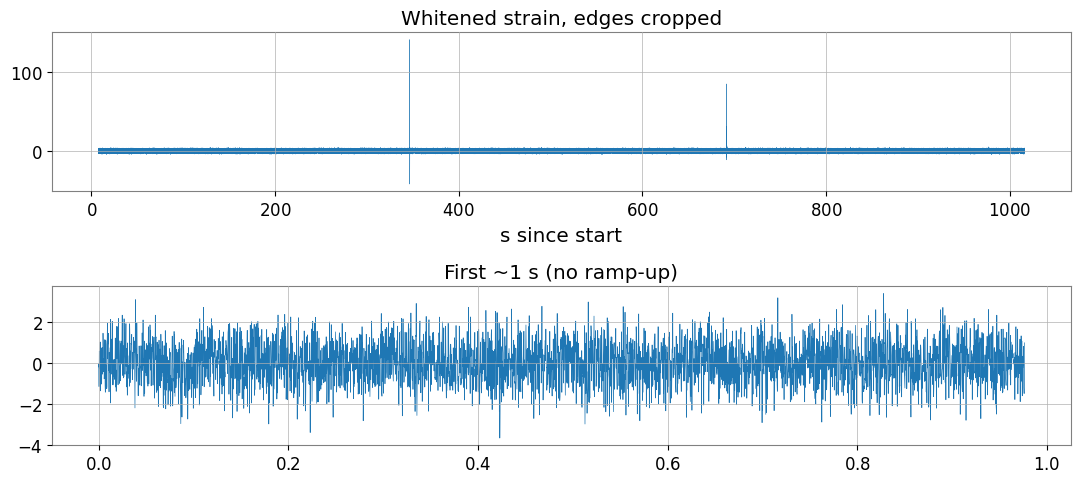

In [4]:
t0, t1 = GPS_START, GPS_START+DURATION
ts = TimeSeries.fetch_open_data(DET, t0, t1, cache=True)
fs = int(ts.sample_rate.value)
w  = ts.whiten(fftlength=4, overlap=2)
w  = w.crop(t0+EDGE_CROP, t1-EDGE_CROP)          # remove filter edge transients
data = w.value; data = data/np.std(data)
WIN_N = WIN_S*fs
print(f"fs={fs} Hz | samples={len(data)} | window={WIN_N} samples | n per variable={WIN_N//P}")

fig, ax = plt.subplots(2, 1, figsize=(11, 5))
ax[0].plot(w.times.value-t0, data, lw=.3); ax[0].set_title("Whitened strain, edges cropped"); ax[0].set_xlabel("s since start")
ax[1].plot(np.arange(4000)/fs, data[:4000], lw=.5); ax[1].set_title("First ~1 s (no ramp-up)")
plt.tight_layout(); plt.savefig("fig2_whitened.png", dpi=150); plt.show()

In [5]:
n_win = len(data)//WIN_N
rec = []
all_sp = []
for i in range(n_win):
    seg = data[i*WIN_N:(i+1)*WIN_N]
    e = window_eigs(seg)
    all_sp.append(unfold_spacings(e))
    rec.append(dict(window=i, gps_start=float(w.times.value[i*WIN_N]),
                    zeta=zeta_metric(e), rbar=mean_ratio(e)))
df = pd.DataFrame(rec); all_sp = np.concatenate(all_sp)
print(f"{n_win} windows | mean zeta = {df.zeta.mean():.4f} | mean <r> = {df.rbar.mean():.4f}")

504 windows | mean zeta = 0.1369 | mean <r> = 0.5226


In [6]:
null = np.array([window_stats(rng.standard_normal(WIN_N)) for _ in range(N_NULL)])
null_z, null_r = null[:, 0], null[:, 1]

# one-sided empirical p-value for the ζ-metric (large = more non-GOE)
df["p_zeta"] = [(1+np.sum(null_z >= z))/(N_NULL+1) for z in df.zeta]
# two-sided for <r> (deviation from null mean)
dev_null = np.abs(null_r-null_r.mean())
df["p_r"] = [(1+np.sum(dev_null >= abs(r-null_r.mean())))/(N_NULL+1) for r in df.rbar]

df["q_zeta"] = false_discovery_control(df.p_zeta.values, method="bh")
df["flag"]   = df.q_zeta < ALPHA_Q
thr99 = np.quantile(null_z, .99)

print(f"Null zeta: mean={null_z.mean():.3f}, 99th pct={thr99:.3f}")
print(f"Observed windows above null 99th pct: {(df.zeta>thr99).sum()} / {n_win} (expect ~{0.01*n_win:.0f} by chance)")
print(f"Flagged at FDR {ALPHA_Q}: {df.flag.sum()} windows")
print("Mean <r>: data %.4f | white-noise null %.4f ± %.4f" % (df.rbar.mean(), null_r.mean(), null_r.std()))
print(df.sort_values("p_zeta").head(10).round(4).to_string(index=False))

Null zeta: mean=0.135, 99th pct=0.230
Observed windows above null 99th pct: 7 / 504 (expect ~5 by chance)
Flagged at FDR 0.05: 0 windows
Mean <r>: data 0.5226 | white-noise null 0.5313 ± 0.0648
 window    gps_start   zeta   rbar  p_zeta    p_r  q_zeta  flag
    341 1238166708.0 0.3255 0.6262  0.0003 0.1480  0.0840 False
    169 1238166364.0 0.3856 0.5528  0.0003 0.7547  0.0840 False
    198 1238166422.0 0.2640 0.4364  0.0017 0.1476  0.2799 False
    397 1238166820.0 0.2529 0.5226  0.0040 0.8940  0.4758 False
      2 1238166030.0 0.2483 0.4272  0.0050 0.1120  0.4758 False
    125 1238166276.0 0.2437 0.3455  0.0057 0.0040  0.4758 False
    471 1238166968.0 0.2389 0.4651  0.0067 0.3126  0.4798 False
    183 1238166392.0 0.2291 0.3973  0.0107 0.0357  0.6718 False
    381 1238166788.0 0.2243 0.3632  0.0143 0.0057  0.7235 False
    113 1238166252.0 0.2205 0.4608  0.0167 0.2786  0.7235 False


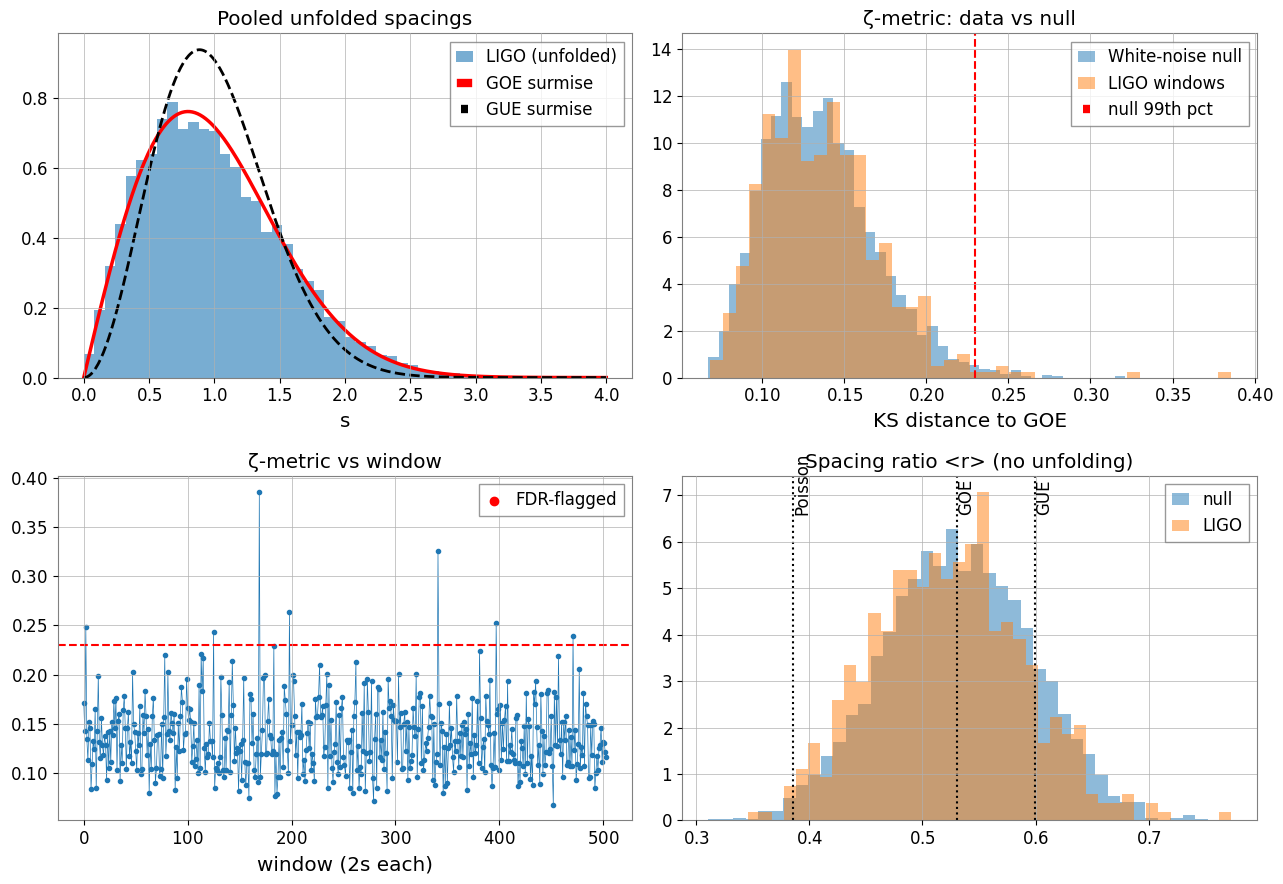

Pooled KS vs GOE: 0.0163 | vs GUE: 0.0788
Wasserstein vs GOE samples: 0.0164


In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
x = np.linspace(0, 4, 400)

ax[0,0].hist(all_sp, bins=50, range=(0, 4), density=True, alpha=.6, label="LIGO (unfolded)")
ax[0,0].plot(x, goe_pdf(x), 'r', lw=2.5, label="GOE surmise")
ax[0,0].plot(x, gue_pdf(x), 'k--', lw=2, label="GUE surmise")
ax[0,0].set_title("Pooled unfolded spacings"); ax[0,0].set_xlabel("s"); ax[0,0].legend()

ax[0,1].hist(null_z, bins=40, density=True, alpha=.5, label="White-noise null")
ax[0,1].hist(df.zeta, bins=40, density=True, alpha=.5, label="LIGO windows")
ax[0,1].axvline(thr99, color='r', ls='--', label="null 99th pct")
ax[0,1].set_title("ζ-metric: data vs null"); ax[0,1].set_xlabel("KS distance to GOE"); ax[0,1].legend()

ax[1,0].plot(df.window, df.zeta, '.-', lw=.5)
ax[1,0].axhline(thr99, color='r', ls='--')
ax[1,0].scatter(df.window[df.flag], df.zeta[df.flag], c='r', zorder=3, label="FDR-flagged")
ax[1,0].set_title("ζ-metric vs window"); ax[1,0].set_xlabel(f"window ({WIN_S}s each)"); ax[1,0].legend()

ax[1,1].hist(null_r, bins=40, density=True, alpha=.5, label="null")
ax[1,1].hist(df.rbar, bins=40, density=True, alpha=.5, label="LIGO")
for v, l in [(0.5307, "GOE"), (0.5996, "GUE"), (0.386, "Poisson")]:
    ax[1,1].axvline(v, ls=':', c='k'); ax[1,1].text(v, ax[1,1].get_ylim()[1]*.9, l, rotation=90)
ax[1,1].set_title("Spacing ratio <r> (no unfolding)"); ax[1,1].legend()

plt.tight_layout(); plt.savefig("fig3_main.png", dpi=150); plt.show()

# pooled comparisons
ref = goe_samples(len(all_sp))
print("Pooled KS vs GOE: %.4f | vs GUE: %.4f" % (kstest(all_sp, goe_cdf).statistic, kstest(all_sp, gue_cdf).statistic))
print("Wasserstein vs GOE samples: %.4f" % wasserstein_distance(all_sp, ref))

 burst amplitude (σ)  detection rate @ null 1% FPR
                0.00                      0.013333
                0.25                      0.026667
                0.50                      0.006667
                1.00                      0.020000
                2.00                      0.013333
                4.00                      0.020000


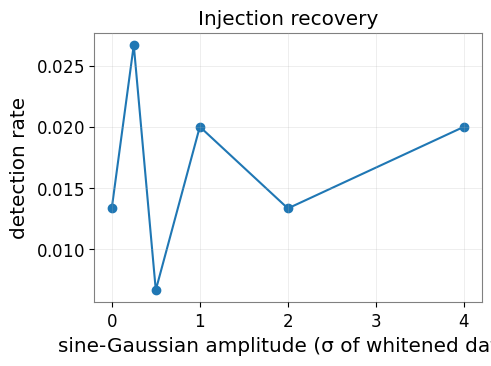

In [8]:
def inject(seg, amp, f0=150, tau=0.05):
    t = np.arange(len(seg))/fs; tc = t[len(t)//2]
    return seg + amp*np.sin(2*np.pi*f0*t)*np.exp(-((t-tc)/tau)**2)

amps = [0, 0.25, 0.5, 1, 2, 4]
n_trials = 150
out = []
for A in amps:
    hits = 0
    for _ in range(n_trials):
        i = rng.integers(0, n_win)
        z, _ = window_stats(inject(data[i*WIN_N:(i+1)*WIN_N], A))
        hits += z > thr99
    out.append(hits/n_trials)
inj = pd.DataFrame({"burst amplitude (σ)": amps, "detection rate @ null 1% FPR": out})
print(inj.to_string(index=False))
plt.figure(figsize=(5, 3.5)); plt.plot(amps, out, 'o-'); plt.xlabel("sine-Gaussian amplitude (σ of whitened data)")
plt.ylabel("detection rate"); plt.title("Injection recovery"); plt.grid(alpha=.3)
plt.savefig("fig4_injection.png", dpi=150, bbox_inches="tight"); plt.show()

        data  KS vs GUE  KS vs GOE  KS vs zeros
  Zeta zeros     0.0616     0.1286          NaN
LIGO windows     0.0788     0.0163       0.1396


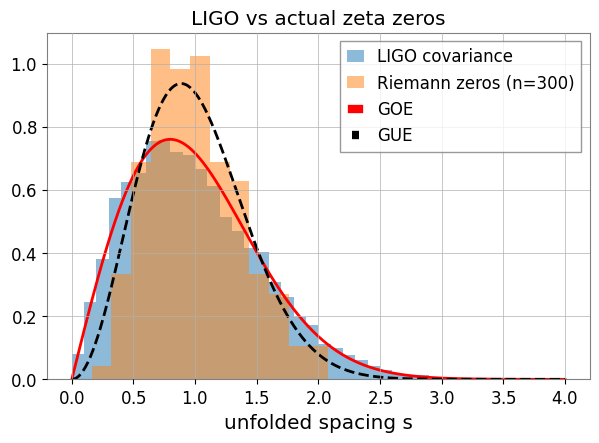

In [9]:
import mpmath as mp
N_ZEROS = 300     # ~tens of seconds
zeros = np.array([float(mp.zetazero(n).imag) for n in range(1, N_ZEROS+1)])
Nsmooth = lambda T: T/(2*np.pi)*np.log(T/(2*np.pi*np.e)) + 7/8   # smooth zero counting fn
z_sp = np.diff(Nsmooth(zeros)); z_sp /= z_sp.mean()

rows = [["Zeta zeros",   kstest(z_sp, gue_cdf).statistic, kstest(z_sp, goe_cdf).statistic, np.nan],
        ["LIGO windows", kstest(all_sp, gue_cdf).statistic, kstest(all_sp, goe_cdf).statistic,
         ks_2samp(all_sp, z_sp).statistic]]
print(pd.DataFrame(rows, columns=["data", "KS vs GUE", "KS vs GOE", "KS vs zeros"]).round(4).to_string(index=False))

plt.figure(figsize=(7, 4.5))
plt.hist(all_sp, bins=40, range=(0, 4), density=True, alpha=.5, label="LIGO covariance")
plt.hist(z_sp, bins=25, range=(0, 4), density=True, alpha=.5, label=f"Riemann zeros (n={N_ZEROS})")
plt.plot(x, goe_pdf(x), 'r', lw=2, label="GOE"); plt.plot(x, gue_pdf(x), 'k--', lw=2, label="GUE")
plt.xlabel("unfolded spacing s"); plt.legend(); plt.title("LIGO vs actual zeta zeros")
plt.savefig("fig5_zeta.png", dpi=150, bbox_inches="tight"); plt.show()

In [14]:
df.to_csv("zeta metric windows.csv", index=False)
inj.to_csv("injection_recovery.csv", index=False)
from google.colab import files
for f in ["zeta metric windows.csv", "injection_recovery.csv", "fig1_sanity.png", "fig2_whitened.png",
          "fig3_main.png", "fig4_injection.png", "fig5_zeta.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>